# 第 7 章配套 Notebook：为什么发放率约等于 ReLU：裂项求和、三种误差、QCFS 与两层网络完整对照

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch07_ann2snn_rate_and_errors.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-02 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-02/notion/notebooks/ch07_ann2snn_rate_and_errors.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有矩阵每一步的中间数值均直接打印并与第 7 章正文手算结果逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 裂项求和恒等式与“截断并量化的 ReLU”曲线（含 $v[0]=\theta/2$ 半阈值初始化与 QCFS 定理验证）

对减法复位 IF 神经元在 $t = 1..T$ 求和：
$$v[T] = v[0] + \sum_{t=1}^{T} z[t] - \theta \sum_{t=1}^{T} s[t] \implies r = \frac{1}{T}\sum_{t=1}^{T} s[t] = \frac{1}{\theta}\left(\bar{z} - \frac{v[T] - v[0]}{T}\right)$$
验证：
1. 对任意输入 $z \in [-0.5, 1.5]$，逐步模拟 IF 神经元算出的真实发放率与裂项恒等式右端误差为 `0.0`；
2. 当输入恒定时，$v[0]=0$ 对应向下取整（Flooring，最大量化误差 $\theta/T$），而 **$v[0]=\theta/2$ 对应四舍五入（Rounding，最大量化误差减半为 $\theta/(2T)$，且区间平均误差为 $0$，即 QCFS Theorem 2）**！

T=4, v[0]=0     : 最大绝对误差 = 0.2480 (理论 1/T = 0.2500), 平均偏差 = -0.1153
T=4, v[0]=theta/2: 最大绝对误差 = 0.1240 (理论 1/2T = 0.1250), 平均偏差 = -0.0089 (趋近 0！)
QCFS Theorem 2 检验 (L=4 源网络转 T=8 SNN, phi=0.5): 均匀分布平均误差 = +0.000000


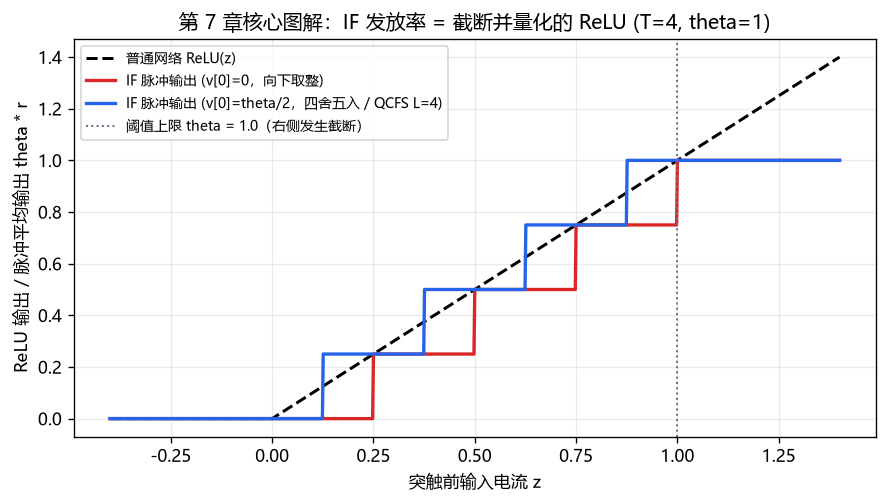

In [2]:
def simulate_if_const(z_arr: np.ndarray, T: int, theta: float = 1.0, v0: float = 0.0, eps: float = 1e-9):
    v = np.full_like(z_arr, v0, dtype=float)
    s_sum = np.zeros_like(z_arr, dtype=float)
    for _ in range(T):
        v_minus = v + z_arr
        s = (v_minus >= theta - eps).astype(float)
        v = v_minus - theta * s
        s_sum += s
    r = s_sum / T
    # 核对裂项求和恒等式：v[T] == v[0] + T*z - theta * s_sum
    lhs = v
    rhs = v0 + T * z_arr - theta * s_sum
    assert np.allclose(lhs, rhs, atol=1e-12)
    return r, v

z_grid = np.linspace(-0.4, 1.4, 901)
T_demo = 4
theta_demo = 1.0

relu_curve = np.maximum(0.0, z_grid)
r_v0_zero, vT_zero = simulate_if_const(z_grid, T=T_demo, theta=theta_demo, v0=0.0)
r_v0_half, vT_half = simulate_if_const(z_grid, T=T_demo, theta=theta_demo, v0=0.5 * theta_demo)

# 核对闭式阶梯公式：theta * clip(floor((z*T + v0)/theta) / T, 0, 1)
closed_zero = theta_demo * np.clip(np.floor((z_grid * T_demo + 0.0 + 1e-9) / theta_demo) / T_demo, 0.0, 1.0)
closed_half = theta_demo * np.clip(np.floor((z_grid * T_demo + 0.5 * theta_demo + 1e-9) / theta_demo) / T_demo, 0.0, 1.0)
assert np.allclose(theta_demo * r_v0_zero, closed_zero)
assert np.allclose(theta_demo * r_v0_half, closed_half)

# 在不发生截断的有效正区间 [0, theta - theta/(2T)] 上统计量化误差均值与最大值
mask_mid = (z_grid >= 0.0) & (z_grid <= 0.875)
err_zero = theta_demo * r_v0_zero[mask_mid] - relu_curve[mask_mid]
err_half = theta_demo * r_v0_half[mask_mid] - relu_curve[mask_mid]
print(f"T={T_demo}, v[0]=0     : 最大绝对误差 = {np.max(np.abs(err_zero)):.4f} (理论 1/T = 0.2500), 平均偏差 = {np.mean(err_zero):+.4f}")
print(f"T={T_demo}, v[0]=theta/2: 最大绝对误差 = {np.max(np.abs(err_half)):.4f} (理论 1/2T = 0.1250), 平均偏差 = {np.mean(err_half):+.4f} (趋近 0！)")

# 验证 QCFS Theorem 1 (T = L = 4, phi = 0.5 -> 误差恒为 0) 与 Theorem 2 (L = 4, T = 8, phi = 0.5 -> 区间期望误差为 0)
L_qcfs = 4
a_qcfs = theta_demo * np.clip(np.floor(z_grid * L_qcfs / theta_demo + 0.5 + 1e-9) / L_qcfs, 0.0, 1.0)
assert np.allclose(theta_demo * r_v0_half, a_qcfs), "QCFS Theorem 1: T=L 时转换估计误差严格为 0！"
z_unif = np.linspace(0.0, theta_demo, 10000, endpoint=False)
a_qcfs_u = theta_demo * np.clip(np.floor(z_unif * L_qcfs / theta_demo + 0.5) / L_qcfs, 0.0, 1.0)
phi_T8_u = theta_demo * np.clip(np.floor(z_unif * 8 / theta_demo + 0.5) / 8, 0.0, 1.0)
print(f"QCFS Theorem 2 检验 (L=4 源网络转 T=8 SNN, phi=0.5): 均匀分布平均误差 = {np.mean(phi_T8_u - a_qcfs_u):+.6f}")

fig, ax = plt.subplots(figsize=(7.5, 4.3), dpi=120)
ax.plot(z_grid, relu_curve, "k--", lw=1.8, label="普通网络 ReLU(z)")
ax.plot(z_grid, theta_demo * r_v0_zero, color="#dc2626", lw=2.0, label="IF 脉冲输出 (v[0]=0，向下取整)")
ax.plot(z_grid, theta_demo * r_v0_half, color="#2563eb", lw=2.0, label="IF 脉冲输出 (v[0]=theta/2，四舍五入 / QCFS L=4)")
ax.axvline(theta_demo, color="#64748b", ls=":", lw=1.2, label="阈值上限 theta = 1.0（右侧发生截断）")
ax.set_xlabel("突触前输入电流 z")
ax.set_ylabel("ReLU 输出 / 脉冲平均输出 theta * r")
ax.set_title("第 7 章核心图解：IF 发放率 = 截断并量化的 ReLU (T=4, theta=1)")
ax.legend(fontsize=8.5)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 2. 为什么复制权重 $W$ 就能工作（验收标准第 4 条）与 `max`、乘法两个数值反例

- **线性层加偏置**：$\frac{1}{T}\sum_{t=1}^T (W \mathbf{s}[t] + \mathbf{b}) = W\left(\frac{1}{T}\sum_{t=1}^T \mathbf{s}[t]\right) + \mathbf{b} = W\mathbf{r} + \mathbf{b}$（严格相等，零误差！）。
- **反例 A（逐时间步取 `max`）**：两路脉冲 `s_1 = [1, 0, 1, 0]`（发放率 `0.5`）与 `s_2 = [0, 1, 0, 1]`（发放率 `0.5`），真实最大值 $\max(0.5, 0.5) = 0.5$，但逐步取最大得 `[1, 1, 1, 1]`，平均发放率变成 **`1.0`（翻倍高估）**！
- **反例 B（逐时间步做乘法）**：同一对交替脉冲序列，各自平均之积为 $0.5 \times 0.5 = 0.25$，但每一步都有一个为 `0`，逐步相乘得 `[0, 0, 0, 0]`，平均变成 **`0.0`（彻底归零）**！

In [3]:
W_lin = np.array([[ 1.2, -0.8],
                  [-0.5,  1.5]])
b_lin = np.array([0.2, -0.1])
S_pair = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [0.0, 1.0],
])  # T=4, s_1=[1,0,1,0], s_2=[0,1,0,1]
r_pair = S_pair.mean(axis=0)  # [0.5, 0.5]

# 1) 线性层穿透验证
avg_of_linear = np.mean([W_lin @ S_pair[t] + b_lin for t in range(4)], axis=0)
linear_of_avg = W_lin @ r_pair + b_lin
print("线性层：逐步算再时间平均 =", avg_of_linear)
print("线性层：先求发放率再乘 W =", linear_of_avg)
assert np.allclose(avg_of_linear, linear_of_avg)

# 2) 反例 A：逐步取 max
true_max_of_rates = np.max(r_pair)                  # max(0.5, 0.5) = 0.5
step_max_seq = np.max(S_pair, axis=1)               # [1, 1, 1, 1]
rate_of_step_max = np.mean(step_max_seq)            # 1.0
print(f"\n反例 A (max)：max(r_1, r_2) = {true_max_of_rates:.2f} != 逐步 max 的平均 {rate_of_step_max:.2f} (脉冲序列 {step_max_seq.astype(int)})")
assert true_max_of_rates == 0.5 and rate_of_step_max == 1.0

# 3) 反例 B：逐步相乘
true_prod_of_rates = r_pair[0] * r_pair[1]          # 0.5 * 0.5 = 0.25
step_prod_seq = S_pair[:, 0] * S_pair[:, 1]         # [0, 0, 0, 0]
rate_of_step_prod = np.mean(step_prod_seq)          # 0.0
print(f"反例 B (乘法)：r_1 * r_2     = {true_prod_of_rates:.2f} != 逐步相乘的平均 {rate_of_step_prod:.2f} (脉冲序列 {step_prod_seq.astype(int)})")
assert true_prod_of_rates == 0.25 and rate_of_step_prod == 0.0


线性层：逐步算再时间平均 = [0.4 0.4]
线性层：先求发放率再乘 W = [0.4 0.4]

反例 A (max)：max(r_1, r_2) = 0.50 != 逐步 max 的平均 1.00 (脉冲序列 [1 1 1 1])
反例 B (乘法)：r_1 * r_2     = 0.25 != 逐步相乘的平均 0.00 (脉冲序列 [0 0 0 0])


## 3. 三种转换误差来源——逐个具体数值手算核对（验收标准第 3 条 + QCFS Section 3 原例）

1. **截断误差（Clipping Error）**：$\theta=1, T=4, v[0]=0, z=1.5 > \theta$ $\implies$ ReLU 输出 `1.5`，SNN 每步都发满也只能输出 `1.0`（误差 `-0.5`，残余电位 $v[4]=2.0$）。
2. **量化误差（Quantization Error）**：$\theta=1, T=4, z=0.45$ $\implies$ ReLU 输出 `0.45`；$v[0]=0$ 时总充电 $1.80$ 只发 1 次得 `0.25`（误差 `-0.20`）；改设 $v[0]=0.5$ 时总电位 $2.30$ 发 2 次得 `0.50`（误差缩至 `+0.05`）。
3. **到达不均匀误差（Unevenness Error，完整复现 QCFS 第 4 页原例）**：前一层两个脉冲神经元在 $T=5$ 步内都固定发出 3 个和 2 个脉冲（平均输出同为 $[0.6, 0.4]^\top$），连接权重 $W=[2, -2]$，$\theta=1, v[0]=0$，故 ANN 输出恒为 $\mathrm{ReLU}(2\times 0.6 - 2\times 0.4) = 0.4$。仅改变脉冲到达的先后次序：
   - **情形 A（均匀交错）**：$s_1=[1,0,1,0,1], s_2=[0,1,0,1,0]$ $\implies$ 发 2 次，输出 **`0.4`**（零误差）；
   - **情形 B（正先负后）**：$s_1=[1,1,1,0,0], s_2=[0,0,0,1,1]$ $\implies$ 前 4 步连发 4 次，末态 $v[5]=-2 < 0$，输出 **`0.8`**（多发翻倍！）；
   - **情形 C（负先正后）**：$s_1=[0,0,1,1,1], s_2=[1,1,0,0,0]$ $\implies$ 只在第 5 步发 1 次，末态 $v[5]=+1$，输出 **`0.2`**（少发一半！）。

In [4]:
def trace_neuron(z_seq, theta=1.0, v0=0.0, eps=1e-9):
    v = v0
    s_list, v_list = [], []
    for z_t in z_seq:
        v_minus = v + z_t
        s = 1 if v_minus >= theta - eps else 0
        v = v_minus - theta * s
        s_list.append(s)
        v_list.append(v)
    return s_list, v_list

# (1) 截断误差：z = 1.5, T = 4, theta = 1.0, v0 = 0.0
s_clip, v_clip = trace_neuron([1.5]*4, theta=1.0, v0=0.0)
print(f"[1. 截断误差] z=1.5 -> s={s_clip}, v={v_clip}, SNN输出={sum(s_clip)/4:.2f} vs ReLU=1.50 (误差={sum(s_clip)/4 - 1.5:+.2f})")
assert sum(s_clip)/4 == 1.0 and np.isclose(v_clip[-1], 2.0)

# (2) 量化误差：z = 0.45, T = 4, theta = 1.0 (对比 v0=0 与 v0=0.5)
s_q0, v_q0 = trace_neuron([0.45]*4, theta=1.0, v0=0.0)
s_qh, v_qh = trace_neuron([0.45]*4, theta=1.0, v0=0.5)
print(f"[2. 量化误差] z=0.45, v0=0.0 -> s={s_q0}, SNN输出={sum(s_q0)/4:.2f} vs ReLU=0.45 (误差={sum(s_q0)/4 - 0.45:+.2f})")
print(f"              z=0.45, v0=0.5 -> s={s_qh}, SNN输出={sum(s_qh)/4:.2f} vs ReLU=0.45 (误差={sum(s_qh)/4 - 0.45:+.2f})")
assert sum(s_q0)/4 == 0.25 and sum(s_qh)/4 == 0.50

# (3) 到达不均匀误差（QCFS Section 3 Page 4 原例：W = [2, -2], T = 5, phi^{l-1} = [0.6, 0.4]）
w_uneven = np.array([2.0, -2.0])
cases = [
    ("情形 A 均匀交错", [1, 0, 1, 0, 1], [0, 1, 0, 1, 0], 0.4),
    ("情形 B 正先负后", [1, 1, 1, 0, 0], [0, 0, 0, 1, 1], 0.8),
    ("情形 C 负先正后", [0, 0, 1, 1, 1], [1, 1, 0, 0, 0], 0.2),
]
print("\n[3. 到达不均匀误差] ANN ReLU 输出恒为 [2, -2] @ [0.6, 0.4]^T = 0.40：")
for name, s1, s2, expected_out in cases:
    S_in = np.column_stack([s1, s2]).astype(float)
    assert np.allclose(S_in.mean(axis=0), [0.6, 0.4])
    z_seq = S_in @ w_uneven
    s_out, v_out = trace_neuron(z_seq, theta=1.0, v0=0.0)
    snn_rate = sum(s_out) / 5.0
    # 验证裂项公式 r = z_bar - (v[T] - v[0]) / T 在输入不均匀时依然 100% 成立！
    formula_rate = np.mean(z_seq) - (v_out[-1] - 0.0) / 5.0
    assert np.isclose(snn_rate, expected_out) and np.isclose(snn_rate, formula_rate)
    print(f"  {name}: z[1..5]={z_seq.astype(int).tolist()} -> 脉冲 s={s_out}, 末态 v[5]={v_out[-1]:+.1f}, SNN输出={snn_rate:.2f} (误差={snn_rate-0.4:+.2f})")


[1. 截断误差] z=1.5 -> s=[1, 1, 1, 1], v=[0.5, 1.0, 1.5, 2.0], SNN输出=1.00 vs ReLU=1.50 (误差=-0.50)
[2. 量化误差] z=0.45, v0=0.0 -> s=[0, 0, 1, 0], SNN输出=0.25 vs ReLU=0.45 (误差=-0.20)
              z=0.45, v0=0.5 -> s=[0, 1, 0, 1], SNN输出=0.50 vs ReLU=0.45 (误差=+0.05)

[3. 到达不均匀误差] ANN ReLU 输出恒为 [2, -2] @ [0.6, 0.4]^T = 0.40：
  情形 A 均匀交错: z[1..5]=[2, -2, 2, -2, 2] -> 脉冲 s=[1, 0, 1, 0, 0], 末态 v[5]=+0.0, SNN输出=0.40 (误差=+0.00)
  情形 B 正先负后: z[1..5]=[2, 2, 2, -2, -2] -> 脉冲 s=[1, 1, 1, 1, 0], 末态 v[5]=-2.0, SNN输出=0.80 (误差=+0.40)
  情形 C 负先正后: z[1..5]=[-2, -2, 2, 2, 2] -> 脉冲 s=[0, 0, 0, 0, 1], 末态 v[5]=+1.0, SNN输出=0.20 (误差=-0.20)


## 4. 阈值选择（最大激活 vs 99.9% 分位数）与逐层权重缩放等价性验证

1. **代数等价验证**（Rueckauer 等 2017 Section 3.2.1）：证明并验证——保持原始权重 $W^{(l)}, \mathbf{b}^{(l)}$ 但把第 $l$ 层阈值设为 $\theta^{(l)}=\lambda^{(l)}$（脉冲幅值记为 $\lambda^{(l)} s^{(l)}[t]$），与把所有层阈值统一设为 $1$、同时按
$$\tilde{W}^{(l)} = \frac{\lambda^{(l-1)}}{\lambda^{(l)}} W^{(l)}, \qquad \tilde{\mathbf{b}}^{(l)} = \frac{1}{\lambda^{(l)}} \mathbf{b}^{(l)} \quad (\lambda^{(0)} = 1)$$
缩放参数，在每一个时间步 $t=1..T$ 发出的二值脉冲序列 $\mathbf{s}^{(l)}[t] \in \{0, 1\}$ **逐位完全相同**！
2. **离群点实验**（对应 Rueckauer 等 2017 Section 3.2.2 Fig. 1）：当 1000 个激活值中混入 1 个极端离群值（如 `23.16`，而 99.9% 分位数仅为 `6.83`）时，在 $T=16$ 下取 99.9% 分位数比取全局最大值均方误差低一个数量级以上！

In [5]:
# 1) 验证“调阈值 theta^{(l)} = lambda^{(l)}”与“统一阈值 1 + 缩放权重 W_tilde, b_tilde”逐步脉冲完全一致
W1_eq = np.array([[ 1.5, -0.5],
                  [ 0.8,  1.2],
                  [-0.6,  1.8]])
b1_eq = np.array([0.2, -0.1, 0.3])
W2_eq = np.array([[ 1.0,  0.6, -0.8],
                  [-0.4,  1.2,  0.5]])
b2_eq = np.array([0.1, -0.2])

lam1, lam2 = 2.4, 2.0  # 第 1、2 层缩放因子 / 阈值
x_in = np.array([0.8, 0.9])
T_eq = 12

# 方案甲：原权重 + 每层阈值设为 lam_l，脉冲乘以 lam_l 传给下一层
v1_a, v2_a = np.full(3, 0.5 * lam1), np.full(2, 0.5 * lam2)
spikes1_a, spikes2_a = [], []
for _ in range(T_eq):
    vm1 = v1_a + (W1_eq @ x_in + b1_eq)
    s1 = (vm1 >= lam1 - 1e-9).astype(float)
    v1_a = vm1 - lam1 * s1
    vm2 = v2_a + (W2_eq @ (lam1 * s1) + b2_eq)
    s2 = (vm2 >= lam2 - 1e-9).astype(float)
    v2_a = vm2 - lam2 * s2
    spikes1_a.append(s1)
    spikes2_a.append(s2)

# 方案乙：全网统一单位阈值 theta = 1.0，权重偏置按 Rueckauer 公式缩放 (lam0 = 1.0)
W1_tilde, b1_tilde = (1.0 / lam1) * W1_eq, (1.0 / lam1) * b1_eq
W2_tilde, b2_tilde = (lam1 / lam2) * W2_eq, (1.0 / lam2) * b2_eq
v1_b, v2_b = np.full(3, 0.5), np.full(2, 0.5)
spikes1_b, spikes2_b = [], []
for _ in range(T_eq):
    vm1 = v1_b + (W1_tilde @ x_in + b1_tilde)
    s1 = (vm1 >= 1.0 - 1e-9).astype(float)
    v1_b = vm1 - 1.0 * s1
    vm2 = v2_b + (W2_tilde @ s1 + b2_tilde)
    s2 = (vm2 >= 1.0 - 1e-9).astype(float)
    v2_b = vm2 - 1.0 * s2
    spikes1_b.append(s1)
    spikes2_b.append(s2)

assert np.array_equal(spikes1_a, spikes1_b) and np.array_equal(spikes2_a, spikes2_b)
assert np.allclose(v1_a / lam1, v1_b) and np.allclose(v2_a / lam2, v2_b)
print("等价性验证通过！12 个时间步内第 1、2 层每一拍二值脉冲序列 100% 逐位一致：")
print("  最终输出还原值 (方案甲 lam2*r2) =", lam2 * np.mean(spikes2_a, axis=0))
print("  最终输出还原值 (方案乙 lam2*r2) =", lam2 * np.mean(spikes2_b, axis=0))

# 2) 模拟复现 Rueckauer 2017 Fig. 1a 的长尾激活分布：20000 个非零激活呈指数衰减（99.9% 分位数约 6.83），混入极少数离群点最高达 23.16
rng_out = np.random.default_rng(7)
acts = np.concatenate([rng_out.exponential(scale=0.99, size=19999), [23.16]])
lam_max = np.max(acts)
lam_p999 = np.percentile(acts, 99.9)
T_low = 16
# 按 Rueckauer 2017 标准 v[0]=0 比较低时间步 T=16 下的转换表现与“哑火率”（原本 >0 却 1 个脉冲都发不出的比例）
approx_max  = lam_max  * np.clip(np.floor(acts * T_low / lam_max)  / T_low, 0.0, 1.0)
approx_p999 = lam_p999 * np.clip(np.floor(acts * T_low / lam_p999) / T_low, 0.0, 1.0)
mse_max   = np.mean((approx_max - acts) ** 2)
mse_p999  = np.mean((approx_p999 - acts) ** 2)
dead_max  = np.mean(approx_max == 0.0) * 100
dead_p999 = np.mean(approx_p999 == 0.0) * 100
assert mse_p999 < mse_max / 3.0
print(f"\n离群点实验 (T={T_low}, v[0]=0):")
print(f"  max-norm   (lambda={lam_max:.2f}, 步长={lam_max/T_low:.3f}): MSE = {mse_max:.4f}, 哑火神经元比例 = {dead_max:.1f}%")
print(f"  99.9%分位数 (lambda={lam_p999:.2f}, 步长={lam_p999/T_low:.3f}): MSE = {mse_p999:.4f}, 哑火神经元比例 = {dead_p999:.1f}% (MSE 降低 {mse_max/mse_p999:.1f} 倍！)")


等价性验证通过！12 个时间步内第 1、2 层每一拍二值脉冲序列 100% 逐位一致：
  最终输出还原值 (方案甲 lam2*r2) = [1.       1.833333]
  最终输出还原值 (方案乙 lam2*r2) = [1.       1.833333]

离群点实验 (T=16, v[0]=0):
  max-norm   (lambda=23.16, 步长=1.448): MSE = 0.4615, 哑火神经元比例 = 76.6%
  99.9%分位数 (lambda=6.66, 步长=0.416): MSE = 0.0674, 哑火神经元比例 = 34.1% (MSE 降低 6.9 倍！)


## 5. 两层小网络完整端到端对照：普通网络输出 vs $T = 4, 8, 16, 32$ 脉冲网络输出

复现第 7 章 7.8 节端到端手算与对照表：
- 输入 $\mathbf{x} = [0.8, 0.6]^\top \in \mathbb{R}^2$；
- 第 1 层（3 个隐藏神经元 + ReLU）：$W^{(1)} = \begin{bmatrix} 1.0 & 0.5 \\ -0.5 & 1.5 \\ 0.5 & -1.0 \end{bmatrix}$，$\mathbf{b}^{(1)} = [0.1, 0.0, 0.1]^\top$ $\implies \mathbf{z}^{(1)} = [1.20, 0.50, -0.10]^\top$，$\mathbf{a}^{(1)} = \mathrm{ReLU}(\mathbf{z}^{(1)}) = [1.20, 0.50, 0.00]^\top$；
- 第 2 层（2 个输出神经元 + ReLU）：$W^{(2)} = \begin{bmatrix} 1.0 & 0.5 & -1.0 \\ -0.5 & 1.5 & 0.5 \end{bmatrix}$，$\mathbf{b}^{(2)} = [0.05, 0.10]^\top$ $\implies \mathbf{z}^{(2)} = [1.50, 0.25]^\top$，$\mathbf{a}^{(2)} = \mathrm{ReLU}(\mathbf{z}^{(2)}) = [1.50, 0.25]^\top$。
- 取逐层最大激活阈值 $\theta^{(1)} = 1.20, \theta^{(2)} = 1.50$（并同时对比 $v[0]=0$ 与半阈值 $v[0]=\theta/2$ 两种初始化，以及输出层脉冲读出 vs 膜电位直接积分读出），并排打印 **$T = 4, 8, 16, 32$** 时的脉冲网络输出与误差！

普通 ANN 第 1 层: z^(1) = [ 1.2  0.5 -0.1] -> a^(1) = ReLU(z^(1)) = [1.2 0.5 0. ]
普通 ANN 第 2 层: z^(2) = [1.5  0.25] -> a^(2) = ReLU(z^(2)) = [1.5  0.25]

================ 两层网络并排对照表 (ANN 精确输出 a^(2) = [1.5000, 0.2500]) ================
  T | [v0=0 脉冲输出]         L2误差 | [v0=theta/2 脉冲输出]   L2误差 | [v0=theta/2 末层积分读出] L2误差
----+--------------------------------+--------------------------------+----------------------------------
  4 | [1.1250, 0.0000]   0.4507 | [1.5000, 0.3750]   0.1250 | [1.5500, 0.4000]     0.1581
  8 | [1.3125, 0.0000]   0.3125 | [1.5000, 0.3750]   0.1250 | [1.4750, 0.1750]     0.0791
 16 | [1.4062, 0.1875]   0.1127 | [1.5000, 0.2812]   0.0313 | [1.5125, 0.2875]     0.0395
 32 | [1.4531, 0.1875]   0.0781 | [1.5000, 0.2812]   0.0313 | [1.4938, 0.2312]     0.0198


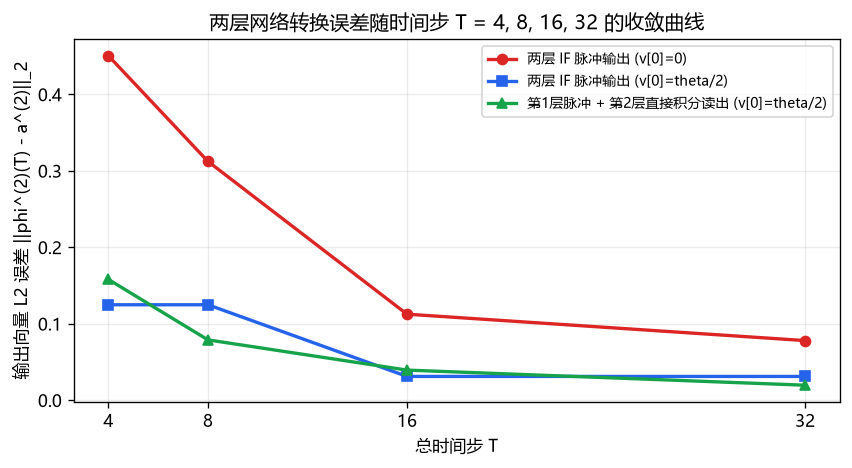

In [6]:
x_net = np.array([0.8, 0.6])
W1_net = np.array([
    [ 1.0,  0.5],
    [-0.5,  1.5],
    [ 0.5, -1.0],
])
b1_net = np.array([0.1, 0.0, 0.1])

W2_net = np.array([
    [ 1.0,  0.5, -1.0],
    [-0.5,  1.5,  0.5],
])
b2_net = np.array([0.05, 0.10])

# 普通 ANN 精确前向
z1_ann = W1_net @ x_net + b1_net
a1_ann = np.maximum(0.0, z1_ann)
z2_ann = W2_net @ a1_ann + b2_net
a2_ann = np.maximum(0.0, z2_ann)
print("普通 ANN 第 1 层: z^(1) =", z1_ann, "-> a^(1) = ReLU(z^(1)) =", a1_ann)
print("普通 ANN 第 2 层: z^(2) =", z2_ann, "-> a^(2) = ReLU(z^(2)) =", a2_ann)
assert np.allclose(a1_ann, [1.20, 0.50, 0.00]) and np.allclose(a2_ann, [1.50, 0.25])

th1_net, th2_net = 1.20, 1.50  # 分别等于各层最大激活（也可以加上安全裕度如 1.60 对比）

def run_2layer_snn(T: int, half_init: bool = True, eps: float = 1e-9):
    v1 = np.full(3, 0.5 * th1_net if half_init else 0.0)
    v2 = np.full(2, 0.5 * th2_net if half_init else 0.0)
    s1_sum = np.zeros(3)
    s2_sum = np.zeros(2)
    z2_acc = np.zeros(2)  # 末层不发脉冲直接积分读出（分类头常用做法）
    for _ in range(T):
        # 第 1 层：直接输入恒定电流 z^(1) = W^(1) x + b^(1)
        vm1 = v1 + (W1_net @ x_net + b1_net)
        s1 = (vm1 >= th1_net - eps).astype(float)
        v1 = vm1 - th1_net * s1
        s1_sum += s1
        x1_psp = th1_net * s1  # 突触后电位

        # 第 2 层：接收第 1 层脉冲流 W^(2) (theta^(1) s^(1)[t]) + b^(2)
        z2_t = W2_net @ x1_psp + b2_net
        z2_acc += z2_t
        vm2 = v2 + z2_t
        s2 = (vm2 >= th2_net - eps).astype(float)
        v2 = vm2 - th2_net * s2
        s2_sum += s2

    phi1 = th1_net * (s1_sum / T)
    phi2_spike = th2_net * (s2_sum / T)
    phi2_mem   = z2_acc / T
    return phi1, phi2_spike, phi2_mem

T_list = [4, 8, 16, 32]
print("\n================ 两层网络并排对照表 (ANN 精确输出 a^(2) = [1.5000, 0.2500]) ================")
print("  T | [v0=0 脉冲输出]         L2误差 | [v0=theta/2 脉冲输出]   L2误差 | [v0=theta/2 末层积分读出] L2误差")
print("----+--------------------------------+--------------------------------+----------------------------------")
errs_zero, errs_half, errs_mem = [], [], []
for T_val in T_list:
    _, p2_z, _      = run_2layer_snn(T_val, half_init=False)
    p1_h, p2_h, m_h = run_2layer_snn(T_val, half_init=True)
    ez = np.linalg.norm(p2_z - a2_ann)
    eh = np.linalg.norm(p2_h - a2_ann)
    em = np.linalg.norm(m_h  - z2_ann)
    errs_zero.append(ez)
    errs_half.append(eh)
    errs_mem.append(em)
    print(f" {T_val:2d} | [{p2_z[0]:.4f}, {p2_z[1]:.4f}]   {ez:.4f} | [{p2_h[0]:.4f}, {p2_h[1]:.4f}]   {eh:.4f} | [{m_h[0]:.4f}, {m_h[1]:.4f}]     {em:.4f}")

fig, ax = plt.subplots(figsize=(7.2, 4.0), dpi=120)
ax.plot(T_list, errs_zero, "o-", color="#dc2626", lw=2.0, label="两层 IF 脉冲输出 (v[0]=0)")
ax.plot(T_list, errs_half, "s-", color="#2563eb", lw=2.0, label="两层 IF 脉冲输出 (v[0]=theta/2)")
ax.plot(T_list, errs_mem,  "^-", color="#16a34a", lw=2.0, label="第1层脉冲 + 第2层直接积分读出 (v[0]=theta/2)")
ax.set_xticks(T_list)
ax.set_xlabel("总时间步 T")
ax.set_ylabel("输出向量 L2 误差 ||phi^(2)(T) - a^(2)||_2")
ax.set_title("两层网络转换误差随时间步 T = 4, 8, 16, 32 的收敛曲线")
ax.legend(fontsize=8.5)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()
